# Clean vs Adversarial Embedding Visualization for MS-TCN-RetNet

Notebook này dùng để visualize embedding của **clean samples** và **adversarial samples** trong cùng một không gian t-SNE/UMAP.

Mục tiêu:

\[
z_i = f_\theta(x_i), \qquad z_i^{adv} = f_\theta(x_i^{adv})
\]

Sau đó fit một projection chung trên:

\[
[z; z^{adv}]
\]

để kiểm tra adversarial embeddings có còn nằm gần clean clusters hay bị kéo sang vùng class khác, đặc biệt là vùng **normal**.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# =========================
# Project path setup
# =========================
# Notebook is expected to be run from a notebooks/ or scripts/ folder.
# Adjust PROJECT_ROOT here if your notebook is located somewhere else.
PROJECT_ROOT = Path("../").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("PROJECT_ROOT:", PROJECT_ROOT)
print("sys.path head:", sys.path[:3])


PROJECT_ROOT: /home/hieutt/Retentive-Network
sys.path head: ['/home/hieutt/Retentive-Network', '/home/hieutt/Retentive-Network/notebooks', '/home/hieutt/miniconda3/envs/torchtf/lib/python39.zip']


In [2]:
# =========================
# 1. User configuration
# =========================
# All paths are defined relative to PROJECT_ROOT from Cell 1.

DATA_DIR = PROJECT_ROOT / "data/2017-subaru-forester/preprocessed"
CHECKPOINT = PROJECT_ROOT / "save/ms_tcn_retnet_free_at_adv_ndcl/ms_tcn_retnet_free_at_adv_ndcl_best_adv_macro_f1.pth"
OUTPUT_DIR = PROJECT_ROOT / "save/tsne_adv_ndcl_notebook"

SPLIT = "test"          # "train", "val", or "test"
METHOD = "tsne"         # "tsne" or "umap"
ATTACK = "pgd"          # "none", "fgsm", or "pgd"

DEVICE = "cuda"         # "cuda" or "cpu"
GPU_ID = 0
SEED = 42

BATCH_SIZE = 256
MAX_PER_CLASS = 300      # balanced sampling for visualization

EPSILON = "4/255"
ATTACK_ALPHA = "1/255"
ATTACK_STEPS = 20
PAYLOAD_INDICES = "2,3,4,5,6,7,8,9"

# t-SNE / UMAP options
PCA_DIM = 50
TSNE_PERPLEXITY = 30.0
UMAP_N_NEIGHBORS = 30
UMAP_MIN_DIST = 0.1

# Safety checks
DATA_DIR = Path(DATA_DIR)
CHECKPOINT = Path(CHECKPOINT)
OUTPUT_DIR = Path(OUTPUT_DIR)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("DATA_DIR   :", DATA_DIR)
print("CHECKPOINT:", CHECKPOINT)
print("OUTPUT_DIR :", OUTPUT_DIR)
print("DATA exists      :", DATA_DIR.exists())
print("CHECKPOINT exists:", CHECKPOINT.exists())


DATA_DIR   : /home/hieutt/Retentive-Network/data/2017-subaru-forester/preprocessed
CHECKPOINT: /home/hieutt/Retentive-Network/save/ms_tcn_retnet_free_at_adv_ndcl/ms_tcn_retnet_free_at_adv_ndcl_best_adv_macro_f1.pth
OUTPUT_DIR : /home/hieutt/Retentive-Network/save/tsne_adv_ndcl_notebook
DATA exists      : True
CHECKPOINT exists: True


In [3]:
# =========================
# 2. Imports and utilities
# =========================
import json
import random
from typing import Dict, List, Tuple

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

try:
    import umap  # pip install umap-learn
except Exception:
    umap = None

from networks.ms_tcn_retnet_torch import MSTCNRetNet


def parse_float_or_fraction(value):
    s = str(value).strip()
    if "/" in s:
        a, b = s.split("/", 1)
        return float(a) / float(b)
    return float(s)


def parse_indices(value: str) -> List[int]:
    return [int(v.strip()) for v in str(value).split(",") if v.strip()]


def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(SEED)

device = torch.device(f"cuda:{GPU_ID}" if DEVICE == "cuda" and torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda:0


In [4]:
# =========================
# 3. Dataset and checkpoint helpers
# =========================
def torch_load_safe(path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=True)
    except TypeError:
        return torch.load(path, map_location=map_location)
    except Exception:
        # Some checkpoints contain argparse objects or older metadata and need weights_only=False
        return torch.load(path, map_location=map_location, weights_only=False)


def load_split(data_dir: Path, split: str) -> Tuple[torch.Tensor, torch.Tensor]:
    pt_path = data_dir / f"{split}.pt"
    if not pt_path.exists():
        raise FileNotFoundError(f"Cannot find {pt_path}")
    obj = torch_load_safe(pt_path, map_location="cpu")
    if "X" not in obj or "y" not in obj:
        raise KeyError(f"{pt_path} must contain keys 'X' and 'y'.")
    return obj["X"].float(), obj["y"].long()


def get_class_names(data_dir: Path, num_classes: int) -> List[str]:
    meta_path = data_dir / "metadata.json"
    if meta_path.exists():
        try:
            meta = json.loads(meta_path.read_text(encoding="utf-8"))
            class_map = meta.get("class_map", {})
            inv = {int(v): Path(k).stem for k, v in class_map.items()}
            return [inv.get(i, "normal" if i == 0 else f"class_{i}") for i in range(num_classes)]
        except Exception as e:
            print("Cannot read class names from metadata:", e)
    return ["normal"] + [f"class_{i}" for i in range(1, num_classes)]


def balanced_indices(y: torch.Tensor, max_per_class: int, seed: int) -> torch.Tensor:
    g = torch.Generator()
    g.manual_seed(seed)
    selected = []
    for c in torch.unique(y).tolist():
        idx = torch.where(y == int(c))[0]
        if len(idx) > max_per_class:
            idx = idx[torch.randperm(len(idx), generator=g)[:max_per_class]]
        selected.append(idx)
    idx_all = torch.cat(selected)
    idx_all = idx_all[torch.randperm(len(idx_all), generator=g)]
    return idx_all


def checkpoint_args_to_dict(ckpt: Dict) -> Dict:
    args = ckpt.get("args", {}) if isinstance(ckpt, dict) else {}
    if args is None:
        return {}
    if not isinstance(args, dict):
        try:
            args = vars(args)
        except Exception:
            args = {}
    return args


def build_model_from_checkpoint(ckpt: Dict, input_dim: int, num_classes: int, device: torch.device) -> MSTCNRetNet:
    args = checkpoint_args_to_dict(ckpt)
    model = MSTCNRetNet(
        input_dim=input_dim,
        num_classes=num_classes,
        hidden_dim=int(args.get("hidden_dim", 64)),
        branch_dim=int(args.get("branch_dim", 32)),
        tcn_dim=int(args.get("tcn_dim", 64)),
        tcn_depth=int(args.get("tcn_depth", 2)),
        tcn_kernel_size=int(args.get("tcn_kernel_size", 3)),
        tcn_dropout=float(args.get("tcn_dropout", 0.1)),
        retention_dim=int(args.get("retention_dim", 64)),
        retention_depth=int(args.get("retention_depth", 2)),
        retention_heads=int(args.get("retention_heads", 4)),
        retention_dropout=float(args.get("retention_dropout", 0.1)),
        ff_expansion=int(args.get("ff_expansion", 4)),
        pool=str(args.get("pool", "mean")),
    ).to(device)

    state = ckpt.get("model_state_dict", ckpt)
    missing, unexpected = model.load_state_dict(state, strict=False)
    if missing:
        print(f"[Warning] Missing keys: {missing[:10]}{' ...' if len(missing) > 10 else ''}")
    if unexpected:
        print(f"[Warning] Unexpected keys: {unexpected[:10]}{' ...' if len(unexpected) > 10 else ''}")
    model.eval()
    return model

In [5]:
# =========================
# 4. Load data and model
# =========================
X_all, y_all = load_split(DATA_DIR, SPLIT)
num_classes = int(torch.max(y_all).item()) + 1
input_dim = int(X_all.shape[2])
class_names = get_class_names(DATA_DIR, num_classes)

idx = balanced_indices(y_all, max_per_class=MAX_PER_CLASS, seed=SEED)
X = X_all[idx]
y = y_all[idx]

ckpt = torch_load_safe(CHECKPOINT, map_location=device)
model = build_model_from_checkpoint(ckpt, input_dim=input_dim, num_classes=num_classes, device=device)

print(f"Loaded split: {SPLIT}")
print(f"Full X: {tuple(X_all.shape)}, selected X: {tuple(X.shape)}")
print(f"num_classes={num_classes}, input_dim={input_dim}")
print("class_names:", class_names)
print("selected label counts:", {int(c): int((y == c).sum()) for c in torch.unique(y)})

Loaded split: test
Full X: (174725, 64, 12), selected X: (3000, 64, 12)
num_classes=10, input_dim=12
class_names: ['normal', 'combined', 'dos', 'fuzzing', 'gear', 'interval', 'rpm', 'speed', 'standstill', 'systematic']
selected label counts: {0: 300, 1: 300, 2: 300, 3: 300, 4: 300, 5: 300, 6: 300, 7: 300, 8: 300, 9: 300}


In [6]:
# =========================
# 5. Payload-only adversarial attacks
# =========================
def make_feature_mask(x: torch.Tensor, indices: List[int]) -> torch.Tensor:
    mask = torch.zeros_like(x)
    mask[:, :, indices] = 1.0
    return mask


def project_payload_linf(x_adv: torch.Tensor, x_orig: torch.Tensor, epsilon: float, payload_indices: List[int]) -> torch.Tensor:
    x_proj = x_orig.clone()
    adv_payload = x_adv[:, :, payload_indices]
    orig_payload = x_orig[:, :, payload_indices]
    adv_payload = torch.max(torch.min(adv_payload, orig_payload + epsilon), orig_payload - epsilon)
    adv_payload = adv_payload.clamp(0.0, 1.0)
    x_proj[:, :, payload_indices] = adv_payload
    return x_proj


def fgsm_attack(model: nn.Module, x: torch.Tensor, y: torch.Tensor, epsilon: float, payload_indices: List[int]) -> torch.Tensor:
    model.eval()
    mask = make_feature_mask(x, payload_indices)
    x_adv = x.detach().clone().requires_grad_(True)
    logits = model(x_adv)
    loss = F.cross_entropy(logits, y)
    grad = torch.autograd.grad(loss, x_adv, retain_graph=False, create_graph=False)[0]
    x_adv = x_adv.detach() + epsilon * grad.sign() * mask
    return project_payload_linf(x_adv, x, epsilon, payload_indices).detach()


def pgd_attack(
    model: nn.Module,
    x: torch.Tensor,
    y: torch.Tensor,
    epsilon: float,
    alpha: float,
    steps: int,
    payload_indices: List[int],
    random_start: bool = True,
) -> torch.Tensor:
    model.eval()
    mask = make_feature_mask(x, payload_indices)
    if random_start:
        delta = torch.empty_like(x).uniform_(-epsilon, epsilon) * mask
        x_adv = project_payload_linf(x + delta, x, epsilon, payload_indices).detach()
    else:
        x_adv = x.detach().clone()

    for _ in range(steps):
        x_adv.requires_grad_(True)
        logits = model(x_adv)
        loss = F.cross_entropy(logits, y)
        grad = torch.autograd.grad(loss, x_adv, retain_graph=False, create_graph=False)[0]
        x_adv = x_adv.detach() + alpha * grad.sign() * mask
        x_adv = project_payload_linf(x_adv, x, epsilon, payload_indices).detach()
    return x_adv.detach()

In [7]:
# =========================
# 6. Feature extraction
# =========================
@torch.no_grad()
def pooled_features_and_logits(model: MSTCNRetNet, x: torch.Tensor):
    """Return penultimate pooled embedding z and logits."""
    if hasattr(model, "forward_features"):
        seq = model.forward_features(x)
        if getattr(model, "pool", "mean") == "mean":
            z = seq.mean(dim=1)
        elif getattr(model, "pool", "mean") == "max":
            z = seq.max(dim=1).values
        else:
            raise ValueError(f"Unsupported pool={getattr(model, 'pool', None)}")
        if hasattr(model, "head_norm"):
            z = model.head_norm(z)
        logits = model.classifier(z)
        return z, logits

    # Fallback: if the model itself supports return_features
    out = model(x, return_features=True)
    if isinstance(out, (tuple, list)) and len(out) == 2:
        z, logits = out
        return z, logits
    raise RuntimeError("Cannot extract features. Add forward_features() or return_features=True to the model.")


def collect_embeddings(model, X, y, device, batch_size, attack, epsilon, alpha, steps, payload_indices):
    clean_z, adv_z = [], []
    clean_pred, adv_pred = [], []
    targets = []

    for start in range(0, len(X), batch_size):
        xb = X[start:start + batch_size].to(device)
        yb = y[start:start + batch_size].to(device)

        with torch.no_grad():
            zc, lc = pooled_features_and_logits(model, xb)

        with torch.enable_grad():
            if attack == "fgsm":
                xadv = fgsm_attack(model, xb, yb, epsilon, payload_indices)
            elif attack == "none":
                xadv = xb.detach().clone()
            else:
                xadv = pgd_attack(model, xb, yb, epsilon, alpha, steps, payload_indices, random_start=True)

        with torch.no_grad():
            za, la = pooled_features_and_logits(model, xadv)

        clean_z.append(zc.detach().cpu())
        adv_z.append(za.detach().cpu())
        clean_pred.append(lc.argmax(dim=1).detach().cpu())
        adv_pred.append(la.argmax(dim=1).detach().cpu())
        targets.append(yb.detach().cpu())

    return {
        "z_clean": torch.cat(clean_z, dim=0).numpy(),
        "z_adv": torch.cat(adv_z, dim=0).numpy(),
        "pred_clean": torch.cat(clean_pred, dim=0).numpy(),
        "pred_adv": torch.cat(adv_pred, dim=0).numpy(),
        "y": torch.cat(targets, dim=0).numpy(),
    }


eps = parse_float_or_fraction(EPSILON)
alpha = parse_float_or_fraction(ATTACK_ALPHA)
payload_indices = parse_indices(PAYLOAD_INDICES)

results = collect_embeddings(
    model=model,
    X=X,
    y=y,
    device=device,
    batch_size=BATCH_SIZE,
    attack=ATTACK,
    epsilon=eps,
    alpha=alpha,
    steps=ATTACK_STEPS,
    payload_indices=payload_indices,
)

z_clean = results["z_clean"]
z_adv = results["z_adv"]
y_np = results["y"]
pred_clean = results["pred_clean"]
pred_adv = results["pred_adv"]

print("z_clean:", z_clean.shape, "z_adv:", z_adv.shape)
print("clean acc selected:", accuracy_score(y_np, pred_clean))
print("adv acc selected:", accuracy_score(y_np, pred_adv))
attack_mask = y_np != 0
print("adv fool-to-benign selected:", float(np.mean(pred_adv[attack_mask] == 0)) if attack_mask.sum() > 0 else 0.0)

z_clean: (3000, 64) z_adv: (3000, 64)
clean acc selected: 0.997
adv acc selected: 0.9933333333333333
adv fool-to-benign selected: 0.006666666666666667


In [8]:
# =========================
# 7. Fit one common t-SNE/UMAP projection on [clean; adversarial]
# =========================
def fit_projection(Z: np.ndarray, method: str, seed: int, pca_dim: int, perplexity: float):
    Z = Z.astype(np.float32)
    if pca_dim > 0 and Z.shape[1] > pca_dim:
        Z = PCA(n_components=pca_dim, random_state=seed).fit_transform(Z)

    if method == "umap":
        if umap is None:
            raise ImportError("umap-learn is not installed. Install with: pip install umap-learn")
        return umap.UMAP(
            n_components=2,
            n_neighbors=UMAP_N_NEIGHBORS,
            min_dist=UMAP_MIN_DIST,
            metric="cosine",
            random_state=seed,
        ).fit_transform(Z)

    return TSNE(
        n_components=2,
        perplexity=perplexity,
        learning_rate="auto",
        init="pca",
        metric="cosine",
        random_state=seed,
    ).fit_transform(Z)


Z = np.vstack([z_clean, z_adv])
coords = fit_projection(Z, method=METHOD, seed=SEED, pca_dim=PCA_DIM, perplexity=TSNE_PERPLEXITY)
coords_clean = coords[:len(z_clean)]
coords_adv = coords[len(z_clean):]

print("coords_clean:", coords_clean.shape)
print("coords_adv:", coords_adv.shape)

coords_clean: (3000, 2)
coords_adv: (3000, 2)


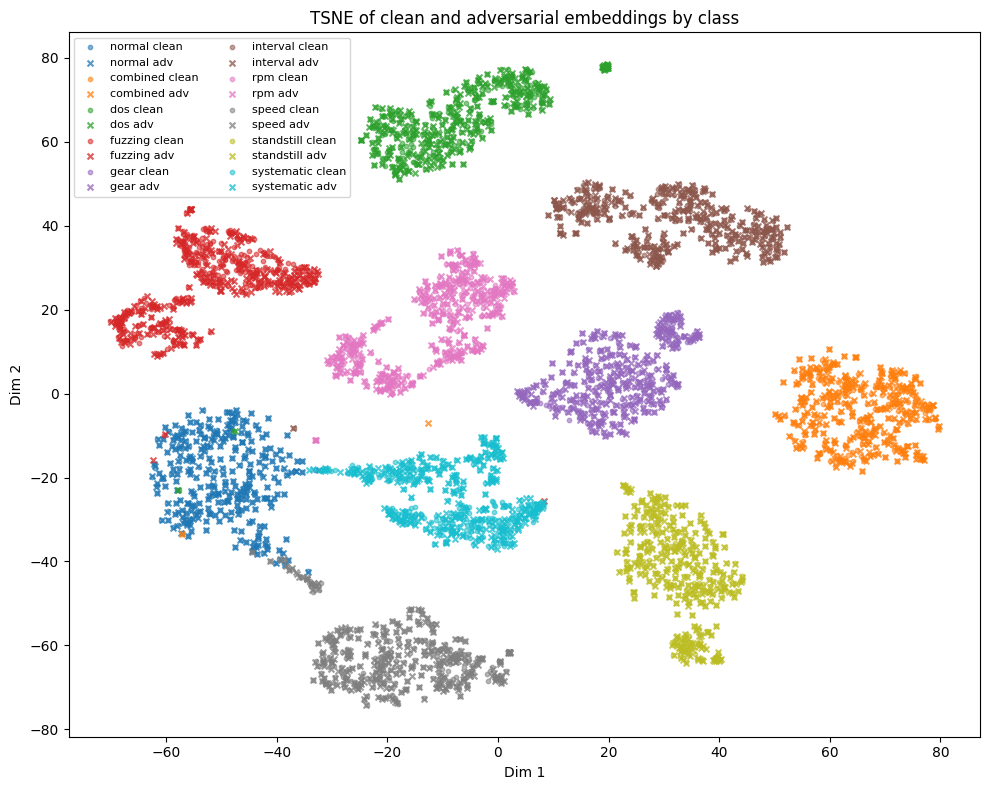

In [9]:
# =========================
# 8. Plot 1: clean and adversarial points by class
# =========================
def plot_by_class(coords_clean, coords_adv, y, class_names, output_path: Path, max_legend_classes: int = 12):
    plt.figure(figsize=(10, 8))
    classes = np.unique(y)
    cmap = plt.get_cmap("tab10" if len(classes) <= 10 else "tab20")

    for i, c in enumerate(classes):
        m = y == c
        label = class_names[int(c)] if int(c) < len(class_names) else f"class_{c}"
        color = cmap(i % cmap.N)
        plt.scatter(coords_clean[m, 0], coords_clean[m, 1], s=10, alpha=0.55, marker="o", color=color, label=f"{label} clean")
        plt.scatter(coords_adv[m, 0], coords_adv[m, 1], s=18, alpha=0.75, marker="x", color=color, label=f"{label} adv")

    plt.title(f"{METHOD.upper()} of clean and adversarial embeddings by class")
    plt.xlabel("Dim 1")
    plt.ylabel("Dim 2")
    if len(classes) <= max_legend_classes:
        plt.legend(fontsize=8, ncol=2, frameon=True)
    plt.tight_layout()
    plt.savefig(output_path.with_suffix(".png"), dpi=300)
    plt.savefig(output_path.with_suffix(".pdf"))
    plt.show()


plot_by_class(coords_clean, coords_adv, y_np, class_names, OUTPUT_DIR / f"{METHOD}_{SPLIT}_clean_adv_by_class")

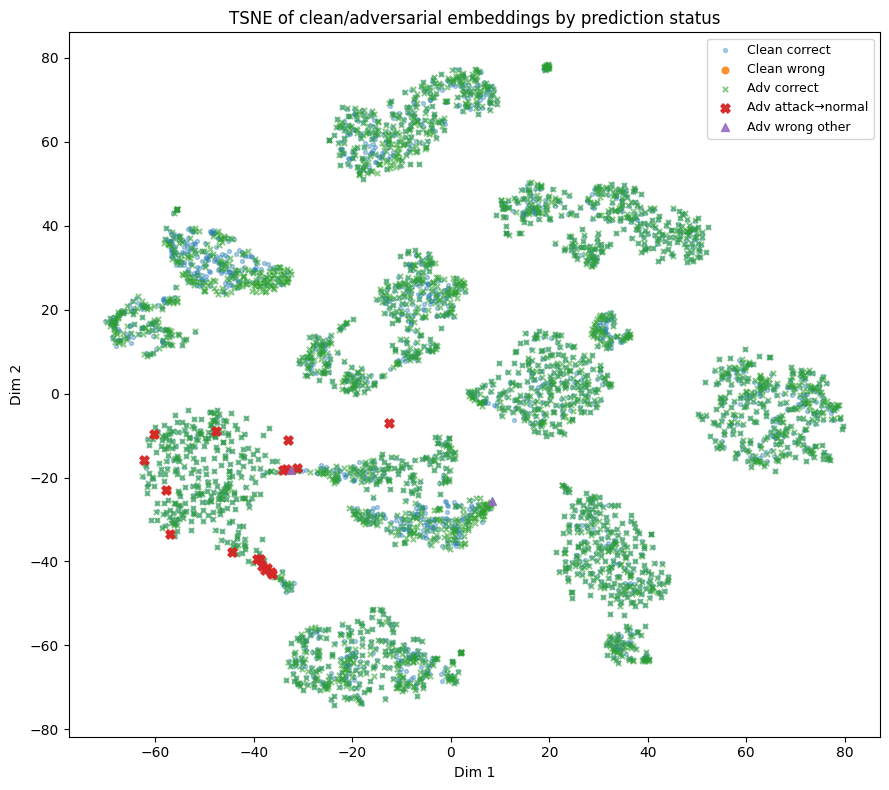

In [10]:
# =========================
# 9. Plot 2: points by prediction status
# =========================
def plot_by_status(coords_clean, coords_adv, y, pred_clean, pred_adv, output_path: Path):
    plt.figure(figsize=(9, 8))

    clean_correct = pred_clean == y
    adv_correct = pred_adv == y
    adv_f2b = (y != 0) & (pred_adv == 0)
    adv_wrong_other = (~adv_correct) & (~adv_f2b)

    plt.scatter(coords_clean[clean_correct, 0], coords_clean[clean_correct, 1], s=8, alpha=0.35, marker="o", label="Clean correct")
    if (~clean_correct).sum() > 0:
        plt.scatter(coords_clean[~clean_correct, 0], coords_clean[~clean_correct, 1], s=22, alpha=0.85, marker="o", label="Clean wrong")

    plt.scatter(coords_adv[adv_correct, 0], coords_adv[adv_correct, 1], s=14, alpha=0.55, marker="x", label="Adv correct")
    if adv_f2b.sum() > 0:
        plt.scatter(coords_adv[adv_f2b, 0], coords_adv[adv_f2b, 1], s=44, alpha=0.95, marker="X", label="Adv attack→normal")
    if adv_wrong_other.sum() > 0:
        plt.scatter(coords_adv[adv_wrong_other, 0], coords_adv[adv_wrong_other, 1], s=32, alpha=0.85, marker="^", label="Adv wrong other")

    plt.title(f"{METHOD.upper()} of clean/adversarial embeddings by prediction status")
    plt.xlabel("Dim 1")
    plt.ylabel("Dim 2")
    plt.legend(fontsize=9, frameon=True)
    plt.tight_layout()
    plt.savefig(output_path.with_suffix(".png"), dpi=300)
    plt.savefig(output_path.with_suffix(".pdf"))
    plt.show()


plot_by_status(coords_clean, coords_adv, y_np, pred_clean, pred_adv, OUTPUT_DIR / f"{METHOD}_{SPLIT}_clean_adv_by_status")

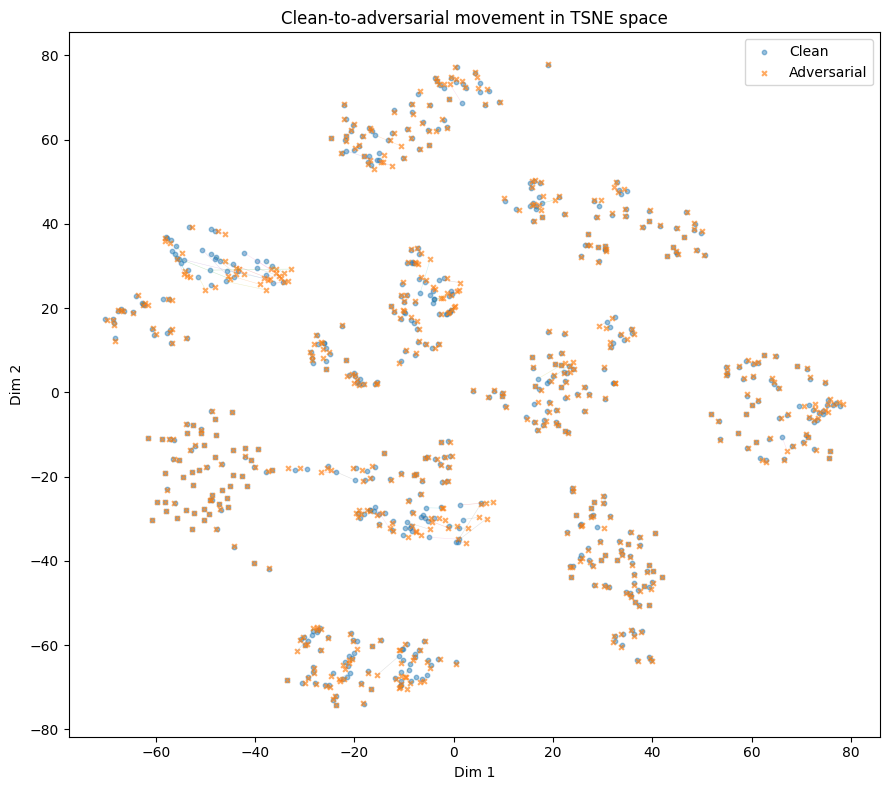

In [11]:
# =========================
# 10. Plot 3: clean-to-adversarial movement
# =========================
def plot_pair_shift(coords_clean, coords_adv, y, output_path: Path, max_pairs: int = 600):
    n = len(y)
    if n > max_pairs:
        rng = np.random.default_rng(SEED)
        idx_plot = rng.choice(n, size=max_pairs, replace=False)
    else:
        idx_plot = np.arange(n)

    plt.figure(figsize=(9, 8))
    plt.scatter(coords_clean[idx_plot, 0], coords_clean[idx_plot, 1], s=10, alpha=0.45, marker="o", label="Clean")
    plt.scatter(coords_adv[idx_plot, 0], coords_adv[idx_plot, 1], s=12, alpha=0.65, marker="x", label="Adversarial")
    for i in idx_plot:
        plt.plot(
            [coords_clean[i, 0], coords_adv[i, 0]],
            [coords_clean[i, 1], coords_adv[i, 1]],
            linewidth=0.35,
            alpha=0.25,
        )
    plt.title(f"Clean-to-adversarial movement in {METHOD.upper()} space")
    plt.xlabel("Dim 1")
    plt.ylabel("Dim 2")
    plt.legend(frameon=True)
    plt.tight_layout()
    plt.savefig(output_path.with_suffix(".png"), dpi=300)
    plt.savefig(output_path.with_suffix(".pdf"))
    plt.show()


plot_pair_shift(coords_clean, coords_adv, y_np, OUTPUT_DIR / f"{METHOD}_{SPLIT}_clean_to_adv_shift")

In [12]:
# =========================
# 11. Quantitative summary and save arrays
# =========================
clean_acc = float(accuracy_score(y_np, pred_clean))
adv_acc = float(accuracy_score(y_np, pred_adv))
clean_macro_f1 = float(f1_score(y_np, pred_clean, average="macro", zero_division=0))
adv_macro_f1 = float(f1_score(y_np, pred_adv, average="macro", zero_division=0))
attack_mask = y_np != 0
adv_f2b = float(np.mean(pred_adv[attack_mask] == 0)) if attack_mask.sum() > 0 else 0.0
avg_shift_2d = float(np.mean(np.linalg.norm(coords_adv - coords_clean, axis=1)))
avg_shift_feat = float(np.mean(np.linalg.norm(z_adv - z_clean, axis=1)))

summary = {
    "split": SPLIT,
    "num_selected": int(len(y_np)),
    "method": METHOD,
    "attack": ATTACK,
    "epsilon": float(eps),
    "attack_alpha": float(alpha),
    "attack_steps": int(ATTACK_STEPS),
    "clean_acc_on_selected": clean_acc,
    "adv_acc_on_selected": adv_acc,
    "clean_macro_f1_on_selected": clean_macro_f1,
    "adv_macro_f1_on_selected": adv_macro_f1,
    "adv_fool_to_benign_on_selected": adv_f2b,
    "avg_clean_to_adv_shift_2d": avg_shift_2d,
    "avg_clean_to_adv_shift_feature": avg_shift_feat,
    "class_names": class_names,
}

print(json.dumps(summary, indent=2))

with open(OUTPUT_DIR / "tsne_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

np.savez_compressed(
    OUTPUT_DIR / "clean_adv_projection.npz",
    coords_clean=coords_clean,
    coords_adv=coords_adv,
    z_clean=z_clean,
    z_adv=z_adv,
    y=y_np,
    pred_clean=pred_clean,
    pred_adv=pred_adv,
    selected_indices=idx.numpy(),
    class_names=np.array(class_names, dtype=object),
)

print("Saved figures and arrays to:", OUTPUT_DIR)

{
  "split": "test",
  "num_selected": 3000,
  "method": "tsne",
  "attack": "pgd",
  "epsilon": 0.01568627450980392,
  "attack_alpha": 0.00392156862745098,
  "attack_steps": 20,
  "clean_acc_on_selected": 0.997,
  "adv_acc_on_selected": 0.9933333333333333,
  "clean_macro_f1_on_selected": 0.9970157436630114,
  "adv_macro_f1_on_selected": 0.993396153784078,
  "adv_fool_to_benign_on_selected": 0.006666666666666667,
  "avg_clean_to_adv_shift_2d": 0.8862892985343933,
  "avg_clean_to_adv_shift_feature": 1.049130916595459,
  "class_names": [
    "normal",
    "combined",
    "dos",
    "fuzzing",
    "gear",
    "interval",
    "rpm",
    "speed",
    "standstill",
    "systematic"
  ]
}
Saved figures and arrays to: /home/hieutt/Retentive-Network/save/tsne_adv_ndcl_notebook


## Cách đọc hình

- Nếu defense tốt, các điểm `x` adversarial nên nằm gần các điểm `o` clean cùng class.
- Nếu attack thành công, nhiều điểm adversarial của attack class sẽ dịch sang vùng normal.
- Hình `prediction status` là hình nên dùng trong paper vì nó làm nổi bật các điểm `Adv attack→normal`.
- Hình `clean-to-adversarial movement` nên dùng cho phân tích hoặc supplementary vì nó trực quan nhưng có thể hơi rối khi số điểm lớn.